In [1]:
# Base
import os
import random as rd

### Visualisation related
import contextily as cx
import geopandas as gpd

# data eng
import h3
import numpy as np
import osmnx as ox
import pandas as pd
import pydeck as pdk
import pypalettes as pypal
import rioxarray as rx
import seaborn as sns
import shapely as shp
from matplotlib import pyplot as plt

import scalenav.data as dt

# module
import scalenav.scale_nav as sd

Using angles for meter grid.


# Introduction to rescaling

This document elaborates on the techniques to downscale geospatial data sets across different resolutions. 

nice blog post: https://strimas.com/post/hexagonal-grids/

point(-0.1275,51.5131)

poly(-0.12496,51.51047,-0.12029,51.51305)


In [2]:
def make_poly(x_min, y_min, x_max, y_max):
    return shp.Polygon(
        [
            (x_min, y_min),
            (x_max, y_min),
            (
                x_max,
                y_max,
            ),
            (x_min, y_max),
        ]
    )

In [3]:
# x = 51.5119
# y = -0.1227

x_1 = -0.12496
x_2 = -0.12029
y_1 = 51.51047
y_2 = 51.51305

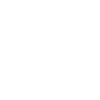

In [4]:
square = make_poly(x_1, y_1, x_2, y_2)
square

In [5]:
y, x = square.centroid.x, square.centroid.y

In [6]:
# res_s2 = 14

# s2_cell = s2.geo_to_s2(lat=y,lon=x,res=res_s2)
# s2_cell_coords = s2.s2_to_geo_boundary(s2_cell)
# s2_cell_geo = Polygon(s2_cell_coords)


In [7]:
print(x, y)

51.51176 -0.12262499999999998


In [8]:
res_h3 = 11

h3_cell = h3.latlng_to_cell(lng=y, lat=x, res=res_h3)
h3_geo = h3.cells_to_h3shape([h3_cell])
h3_geo

<LatLngPoly: [6]>

In [9]:
h3_d = np.round(np.sqrt(h3.cell_area(h3_cell, unit="m^2")), 2)
h3_d
# np.sqrt(h3.cell_area(h=h3_cell,unit="m^2"))

np.float64(43.84)

In [10]:
# relative neighbors

i_range = range(-4, 4)
j_range = range(-4, 4)

coords = [(i, j) for i in i_range for j in j_range]

ref_cell = h3.cell_to_local_ij(origin=h3_cell, h=h3_cell)

# coords
neighbs = [
    h3.local_ij_to_cell(origin=h3_cell, i=ref_cell[0] + id[0], j=ref_cell[1] + id[1])
    for id in coords
]
neighbs[0:5]

['8b194ad3245efff',
 '8b194ad324edfff',
 '8b194ad324e8fff',
 '8b194ad324eafff',
 '8b194ad324c1fff']

In [11]:
ref_cell[0]

-5681

In [12]:
neighbs_geo = h3.cells_to_h3shape(neighbs)

In [13]:
# relative coordinates of the neighbors if approximating the shape with the h3 function

neighbs = [
    h3.cell_to_local_ij(origin=h3_cell, h=cell)
    for cell in h3.geo_to_cells(square, res=11)
]

neighb_id = [(neighb[0] - ref_cell[0], neighb[1] - ref_cell[1]) for neighb in neighbs]

In [14]:
print(len(neighb_id))
neighb_id[0:5]

49


[(-2, -4), (3, 4), (-2, -2), (2, 1), (2, 3)]

## Approximating other shapes with hexes

In [15]:
rast_to_h3 = {"100": 12, "1000": 11, "10000": 9}

In [ ]:
res_h3 = 12

x = 51.51176
y = -0.1227

h3_cell = h3.latlng_to_cell(lng=y, lat=x, res=res_h3)
h3_geo = h3.cells_to_h3shape([h3_cell])

gpd.GeoSeries(
    [h3_geo], crs="EPSG:4326"
).explore()  # should show a hex over Covent garden in London

# Getting the ij neighbors h3 ids.

i_range = range(-4, 5)
j_range = range(-4, 5)

coords = [(i, j) for i in i_range for j in j_range]
# coords
ref_cell = h3.cell_to_local_ij(origin=h3_cell, h=h3_cell)

neighbs = [
    h3.local_ij_to_cell(origin=h3_cell, i=ref_cell[0] + id[0], j=ref_cell[1] + id[1])
    for id in neighb_id
]
neighbs_geo = h3.cells_to_h3shape(neighbs)

# plots in the Atlantic Ocean
gpd.GeoSeries([h3_geo, neighbs_geo, square], crs="EPSG:4326").explore()

In [19]:
[x for x in coords if x in neighb_id]

[(-3, -4),
 (-3, -3),
 (-3, -2),
 (-3, -1),
 (-3, 0),
 (-3, 1),
 (-3, 2),
 (-2, -4),
 (-2, -3),
 (-2, -2),
 (-2, -1),
 (-2, 0),
 (-2, 1),
 (-2, 2),
 (-1, -3),
 (-1, -2),
 (-1, -1),
 (-1, 0),
 (-1, 1),
 (-1, 2),
 (-1, 3),
 (0, -3),
 (0, -2),
 (0, -1),
 (0, 0),
 (0, 1),
 (0, 2),
 (0, 3),
 (1, -3),
 (1, -2),
 (1, -1),
 (1, 0),
 (1, 1),
 (1, 2),
 (1, 3),
 (2, -2),
 (2, -1),
 (2, 0),
 (2, 1),
 (2, 2),
 (2, 3),
 (2, 4),
 (3, -2),
 (3, -1),
 (3, 0),
 (3, 1),
 (3, 2),
 (3, 3),
 (3, 4)]

### Naive approach

In [ ]:
def plot_df(df, column=None, ax=None):
    "Plot based on the `geometry` column of a GeoPandas dataframe"
    df = df.copy()
    df = df.to_crs(epsg=3857)  # web mercator

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    df.plot(
        ax=ax,
        alpha=0.5,
        edgecolor="k",
        column=column,
        categorical=True,
        legend=True,
        legend_kwds={"loc": "upper left"},
    )
    cx.add_basemap(ax, crs=df.crs, source=cx.providers.CartoDB.Positron)


def plot_shape(shape, ax=None):
    df = gpd.GeoDataFrame({"geometry": [shape]}, crs="EPSG:4326")
    plot_df(df, ax=ax)


def plot_cells(cells, ax=None):
    shape = h3.cells_to_h3shape(cells)
    plot_shape(shape, ax=ax)


def plot_shape_and_cells(shape, res=9):
    fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
    plot_shape(shape, ax=axs[0])
    plot_cells(h3.h3shape_to_cells(shape, res), ax=axs[1])
    fig.tight_layout()

In [21]:
child_num = 7
res_ = 3

In [22]:
test_grid = [-15.161, 0.725, 10.371, 18.208]

bbox_polygon = shp.geometry.box(*test_grid)
print(bbox_polygon.wkt)

POLYGON ((10.371 0.725, 10.371 18.208, -15.161 18.208, -15.161 0.725, 10.371 0.725))


In [23]:
h3_shape = h3.geo_to_h3shape(bbox_polygon)

In [24]:
h3_shape_cells = h3.h3shape_to_cells(h3_shape, res=res_)

In [25]:
h3_df = pd.DataFrame(pd.Series(h3_shape_cells), columns=["h3_id"], dtype="str")

# with polars
# h3_pl = pl.DataFrame(h3_df)

In [26]:
len(h3_shape_cells)

530

In [27]:
h3_df["geom"] = gpd.GeoSeries(h3_df.h3_id.apply(lambda x: h3.cells_to_h3shape([x])))
h3_df = gpd.GeoDataFrame(h3_df, geometry="geom")

## Data manipulations

adding some randomly sampled data

In [28]:
alpha = 1
h3_df["values_e"] = [rd.expovariate(lambd=2 * alpha) for x in h3_df.h3_id]

h3_df["values_i"] = [rd.expovariate(lambd=alpha) for x in h3_df.h3_id]

h3_df = sd.add_geom(h3_df)

In [29]:
h3_df.explore(column="values_e")

In [30]:
h3_df["child"] = h3_df.h3_id.apply(h3.cell_to_children)

In [31]:
h3_df_expl = (
    h3_df[["child", "values_i", "values_e"]]
    .explode("child")
    .rename(columns={"child": "h3_id"})
)
h3_df_expl.head()

,h3_id,values_i,values_e
0,8454041ffffffff,0.547321,0.30526
0,8454043ffffffff,0.547321,0.30526
0,8454045ffffffff,0.547321,0.30526
0,8454047ffffffff,0.547321,0.30526
0,8454049ffffffff,0.547321,0.30526


In [32]:
h3_df_expl["values_e"] = (
    h3_df_expl[["h3_id", "values_e"]]
    .filter(regex="_e")
    .mul({"values_e": 1 / child_num})
)

In [33]:
h3_df_expl = sd.add_geom(h3_df_expl)

In [34]:
h3_df_expl.explore(column="values_e")

In [35]:
osm_admin = ox.geocode_to_gdf(query="Ile de France")
# osm_poly = h3.latlng_to_cell(osm_admin,res=res_)
osm_admin.explore()

In [36]:
osm_df = pd.DataFrame()

In [37]:
osm_cells = (
    osm_admin.geometry.apply(lambda x: h3.geo_to_cells(x, res=6))
    .explode()
    .reset_index(drop=True)
)
osm_cells

0      861fb5417ffffff
1      861fb43a7ffffff
2      861fb0a1fffffff
3      861fb479fffffff
4      861fb54a7ffffff
            ...       
366    861fb08b7ffffff
367    861fb0cf7ffffff
368    861fb6367ffffff
369    861fb4287ffffff
370    861fb46c7ffffff
Name: geometry, Length: 371, dtype: str

In [38]:
osm_df["compact"] = pd.Series(h3.compact_cells(osm_cells), index=None)

In [39]:
osm_df.head()

,compact
0,861fb5417ffffff
1,861fb0af7ffffff
2,861fb0307ffffff
3,861fb450fffffff
4,861fb6a2fffffff


In [40]:
osm_df["geom"] = osm_df.compact.apply(lambda x: h3.cells_to_h3shape([x]))

osm_df = gpd.GeoDataFrame(osm_df, geometry="geom", crs="EPSG:4326")

In [41]:
osm_df.explore()

### Projecting crops 

In [42]:
mapspam_dir = "/Users/cenv1069/Documents/agriculture/mapspam/spam2017v2r1_ssa_val_prod/"

mapspan_files = os.listdir(mapspam_dir)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/cenv1069/Documents/agriculture/mapspam/spam2017v2r1_ssa_val_prod/'

In [ ]:
mapspam = rx.open_rasterio(
    mapspam_dir + mapspan_files[0],
)

In [ ]:
mapspam

<xarray.DataArray (band: 1, y: 2160, x: 4320)> Size: 37MB
[9331200 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 35kB -180.0 -179.9 -179.8 ... 179.8 179.9 180.0
  * y            (y) float64 17kB 89.96 89.88 89.79 ... -89.79 -89.87 -89.96
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     -1.0
    scale_factor:   1.0
    add_offset:     0.0

In [ ]:
mapspam_df_ = (
    mapspam[0, :, :]
    .to_pandas()
    .melt(ignore_index=False)
    .reset_index()
    .rename(columns={"value": "value_var"})
)

In [ ]:
mapspam_df_.head()

,y,x,value_var
0,89.958333,-179.958334,-1.0
1,89.875000,-179.958334,-1.0
2,89.791667,-179.958334,-1.0
3,89.708334,-179.958334,-1.0
4,89.625001,-179.958334,-1.0


In [ ]:
mapspam_df_raw = mapspam_df_[mapspam_df_.value_var > 0].reset_index(drop=True)
# mapspam_df = mapspam_df_[mapspam_df_.value_var>0].reset_index(drop=True)

<Axes: >

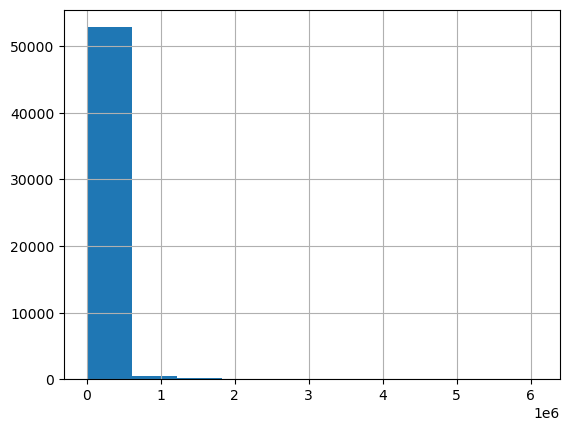

In [ ]:
mapspam_df_raw.value_var.hist()

In [ ]:
res_crop = 6

In [ ]:
# def get_square(h3_cell: str, d: float = 10000):

#     h3_d = np.round(np.sqrt(h3.cell_area(h3_cell,unit="m^2")),2)
#     frag = int(np.ceil(d/h3_d))

#     h3_ref = h3.cell_to_local_ij(origin=h3_cell,h=h3_cell)

#     i_range = range(-frag,frag+1)
#     j_range = range(-frag,frag+1)

#     coords = [(i,j) for i in i_range for j in j_range]
#     # coords
#     ref_cell = h3.cell_to_local_ij(origin=h3_cell,h=h3_cell)

#     return [h3.local_ij_to_cell(origin=h3_cell,i=ref_cell[0]+id[0],j=ref_cell[1]+id[1]) for id in coords]

In [ ]:
mapspam_df_raw.head()

,y,x,value_var
0,13.375306,-16.792319,3647.500000
1,13.291973,-16.792319,11340.200195
2,14.291969,-16.708987,63.299999
3,14.208636,-16.708987,189.699997
4,14.125303,-16.708987,253.000000


In [ ]:
# get_square("8854a93225fffff")

In [ ]:
mapspam_df_raw["geom"] = mapspam_df_raw.filter(regex="h3_id_").apply(
    h3.cells_to_h3shape
)

mapspam_gdf = gpd.GeoDataFrame(mapspam_df
                               ,geometry="geom"
                               ,crs="EPSG:4326")

mapspam_gdf.iloc[0:100].explore(column="value")
mapspam_gdf.head()

In [ ]:
try:
    mapspam_df_raw.drop(labels=["h3_id"], axis={0}, inplace=True)
except KeyError:
    print("Nothing to remove, skipping")
mapspam_df_raw["h3_id"] = mapspam_df_raw.apply(
    lambda row: h3.latlng_to_cell(row["y"], row["x"], res=res_crop), axis=1
)
mapspam_df_raw.head()

,y,x,value_var,geom,h3_id
0,13.375306,-16.792319,3647.500000,NaN,8654a9337ffffff
1,13.291973,-16.792319,11340.200195,NaN,8654a931fffffff
2,14.291969,-16.708987,63.299999,NaN,8654ad387ffffff
3,14.208636,-16.708987,189.699997,NaN,8654ad2a7ffffff
4,14.125303,-16.708987,253.000000,NaN,8654ad2afffffff


In [ ]:
mapspam_df = (
    mapspam_df_raw[["h3_id", "value_var"]].groupby("h3_id").agg("sum").reset_index()
)
mapspam_df.head()

,h3_id,value_var
0,865280477ffffff,590.099976
1,865280807ffffff,1376.800049
2,86528080fffffff,524.500000
3,8652808c7ffffff,1311.199951
4,8652808d7ffffff,1901.199951


In [ ]:
compact_geo = sd.add_geom(mapspam_df)

In [ ]:
compact_geo.shape

(53680, 3)

In [ ]:
compact_geo["log_value_var"] = np.round(np.log1p(compact_geo["value_var"]))

In [ ]:
compact_geo.head()

,h3_id,value_var,geom,log_value_var
0,865280477ffffff,590.099976,"POLYGON ((38.27947 12.86167, 38.29737 12.83463...",6.0
1,865280807ffffff,1376.800049,"POLYGON ((38.5914 13.4915, 38.57351 13.51876, ...",7.0
2,86528080fffffff,524.500000,"POLYGON ((38.5914 13.4915, 38.57484 13.46133, ...",6.0
3,8652808c7ffffff,1311.199951,"POLYGON ((38.57751 13.34657, 38.59536 13.31938...",7.0
4,8652808d7ffffff,1901.199951,"POLYGON ((38.57751 13.34657, 38.5431 13.34362,...",8.0


In [ ]:
compact_geo.loc[0:1000].explore(column="log_value_var")

In [ ]:
compact_geo.head()

,h3_id,value_var,geom,log_value_var
0,865280477ffffff,590.099976,"POLYGON ((38.27947 12.86167, 38.29737 12.83463...",6.0
1,865280807ffffff,1376.800049,"POLYGON ((38.5914 13.4915, 38.57351 13.51876, ...",7.0
2,86528080fffffff,524.500000,"POLYGON ((38.5914 13.4915, 38.57484 13.46133, ...",6.0
3,8652808c7ffffff,1311.199951,"POLYGON ((38.57751 13.34657, 38.59536 13.31938...",7.0
4,8652808d7ffffff,1901.199951,"POLYGON ((38.57751 13.34657, 38.5431 13.34362,...",8.0


In [ ]:
compact_geo_downscaled = sd.change_scale(grid=compact_geo, level=-3)
compact_geo_downscaled["log_value_var"] = np.round(
    np.log1p(compact_geo_downscaled["value_var"]), decimals=2
)
compact_geo_downscaled.head()

Skipping geom


,h3_id,child_cells,value_var,log_value_var
0,835280fffffffff,"[8452805ffffffff, 8452809ffffffff, 845280dffff...",4.969470e+04,10.81
1,835282fffffffff,"[8452821ffffffff, 8452823ffffffff, 8452825ffff...",1.189984e+06,13.99
2,835283fffffffff,"[8452831ffffffff, 8452835ffffffff, 8452837ffff...",3.338324e+05,12.72
3,835284fffffffff,"[8452841ffffffff, 8452843ffffffff, 8452845ffff...",1.562956e+06,14.26
4,835285fffffffff,"[8452853ffffffff, 845285dffffffff]",1.291540e+04,9.47


In [ ]:
max_geom = np.min([50_000, compact_geo_downscaled.shape[0]])

compact_geo_downscaled_sub = sd.add_geom(compact_geo_downscaled.loc[0:max_geom].copy())

compact_geo_downscaled_sub.reset_index(drop=True, inplace=True)

compact_geo_downscaled_sub.head()

,h3_id,child_cells,value_var,log_value_var,geom
0,835280fffffffff,"[8452805ffffffff, 8452809ffffffff, 845280dffff...",4.969470e+04,10.81,"POLYGON ((37.97019 12.83405, 38.46072 12.47793..."
1,835282fffffffff,"[8452821ffffffff, 8452823ffffffff, 8452825ffff...",1.189984e+06,13.99,"POLYGON ((37.27428 11.9689, 37.76603 11.61796,..."
2,835283fffffffff,"[8452831ffffffff, 8452835ffffffff, 8452837ffff...",3.338324e+05,12.72,"POLYGON ((38.35619 11.87175, 38.83967 11.52114..."
3,835284fffffffff,"[8452841ffffffff, 8452843ffffffff, 8452845ffff...",1.562956e+06,14.26,"POLYGON ((38.07384 13.44699, 38.67299 13.69993..."
4,835285fffffffff,"[8452853ffffffff, 845285dffffffff]",1.291540e+04,9.47,"POLYGON ((39.75747 13.58785, 39.8701 14.19935,..."


In [ ]:
# compact_geo.to_file("outputs/compact_geo.geojson")

### Color palette

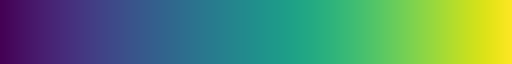

In [ ]:
viridis = sns.color_palette("viridis", as_cmap=True)
viridis

In [ ]:
bmlunge = pypal.load_cmap("Bmlunge")
bmlunge.N

6

In [ ]:
def cmap(input, palette):
    m = np.max(input.to_list())
    l = palette.N
    print(f"Max input : {m}, palette colors : {l}")
    return [[int(255 * j) for j in palette(int(x / m * l))] for x in input]

In [ ]:
unique_vals = pd.Series(compact_geo_downscaled["log_value_var"].unique())
unique_vals.head()

0    10.81
1    13.99
2    12.72
3    14.26
4     9.47
dtype: float32

In [ ]:
cols = cmap(
    compact_geo_downscaled_sub["log_value_var"], palette=bmlunge
)  # pd.Series([[255*j for j in x] for x in bmlunge(compact_geo_downscaled["log_value"])])
compact_geo_downscaled_sub["color"] = cols

Max input : 18.690000534057617, palette colors : 6


In [ ]:
compact_geo_downscaled_sub.head()

,h3_id,child_cells,value_var,log_value_var,geom,color
0,835280fffffffff,"[8452805ffffffff, 8452809ffffffff, 845280dffff...",4.969470e+04,10.81,"POLYGON ((37.97019 12.83405, 38.46072 12.47793...","[52, 170, 182, 255]"
1,835282fffffffff,"[8452821ffffffff, 8452823ffffffff, 8452825ffff...",1.189984e+06,13.99,"POLYGON ((37.27428 11.9689, 37.76603 11.61796,...","[61, 118, 136, 255]"
2,835283fffffffff,"[8452831ffffffff, 8452835ffffffff, 8452837ffff...",3.338324e+05,12.72,"POLYGON ((38.35619 11.87175, 38.83967 11.52114...","[61, 118, 136, 255]"
3,835284fffffffff,"[8452841ffffffff, 8452843ffffffff, 8452845ffff...",1.562956e+06,14.26,"POLYGON ((38.07384 13.44699, 38.67299 13.69993...","[61, 118, 136, 255]"
4,835285fffffffff,"[8452853ffffffff, 845285dffffffff]",1.291540e+04,9.47,"POLYGON ((39.75747 13.58785, 39.8701 14.19935,...","[52, 170, 182, 255]"


In [ ]:
# viewport = pdk.data_utils.compute_view(points=compact_geo_downscaled[['x', 'y']], view_proportion=0.9)
viewport = pdk.ViewState(longitude=0, latitude=0, zoom=3)
# auto_zoom_map = pdk.Deck(layers=[], initial_view_state=viewport)
# auto_zoom_map.show()

In [ ]:
# scaled_layer = pdk.Layer(
#     "GeoJsonLayer",
#     compact_geo_downscaled_sub,
#     pickable=True,
#     extruded=False,
#     filled=True,
#     stroked=True,
#     opacity=.6,
#     get_geometry = "geom",
#     get_fill_color = "color", #"[255*log_value/20,100,120]",
#     get_line_color= [255, 255, 255, 0],
#     line_width_min_pixels=1,
#     )

h3_layer = pdk.Layer(
    "H3HexagonLayer",
    compact_geo_downscaled_sub,
    pickable=True,
    stroked=True,
    filled=True,
    opacity=0.5,
    extruded=False,
    get_hexagon="h3_id",
    get_fill_color="color",
    get_line_color=[0, 0, 0, 0],
    line_width_min_pixels=1,
)

# raster_centr_layer = pdk.Layer(
#     "ScatterplotLayer",
#     mapspam_df_raw,
#     pickable=True,
#     opacity=0.3,
#     stroked=True,
#     filled=True,
#     radius_scale=1,
#     radius_min_pixels=4,
#     radius_max_pixels=5,
#     line_width_min_pixels=1,
#     get_position=["x","y"],
#     get_radius=5,
#     get_fill_color=[255, 140, 0],
#     get_line_color=[0, 0, 0, 0],
# )

r = pdk.Deck(layers=[h3_layer], initial_view_state=viewport, tooltip=True)

# h3_layer

# Create an HTML header to display the year
# display_el = ipywidgets.HTML('<h1>Cropland in Sub-Saharan africa</h1>')
# display(display_el)
# Show the current visualization
# r.show()

In [ ]:
r.to_html("../../deck_maps/cropland_downscaled.html", iframe_height=800)

## Algorightm ameliorations

In [ ]:
# mapspam_harv_area = glob.glob("mapspam/spam2017v2r1_ssa_harv_area/*")
# from re import search
# mapspam_harv_area_sel = [x for x in mapspam_harv_area if search(string=x,pattern="TEAS")]
# mapspam_harv_area_sel
# mapsmam_out_path = "mapspam_teas_ha.geojson"

teas_grid = mapspam_df_raw.copy()
# sn.rast_to_centroid(out_path=mapsmam_out_path,tiff_paths=mapspam_harv_area_sel[1:2]).reset_index(inplace=False,drop=True)

print(teas_grid.shape)

teas_grid.head(3)

(53680, 5)


,y,x,value_var,geom,h3_id
0,13.375306,-16.792319,3647.500000,NaN,8654a9337ffffff
1,13.291973,-16.792319,11340.200195,NaN,8654a931fffffff
2,14.291969,-16.708987,63.299999,NaN,8654ad387ffffff


In [ ]:
teas_grid = gpd.GeoDataFrame(
    teas_grid,
    geometry=teas_grid.apply(lambda row: shp.Point(row["x"], row["y"]), axis=1),
    crs=4326,
)
teas_grid.head()

,y,x,value_var,geom,h3_id,geometry
0,13.375306,-16.792319,3647.500000,NaN,8654a9337ffffff,POINT (-16.79232 13.37531)
1,13.291973,-16.792319,11340.200195,NaN,8654a931fffffff,POINT (-16.79232 13.29197)
2,14.291969,-16.708987,63.299999,NaN,8654ad387ffffff,POINT (-16.70899 14.29197)
3,14.208636,-16.708987,189.699997,NaN,8654ad2a7ffffff,POINT (-16.70899 14.20864)
4,14.125303,-16.708987,253.000000,NaN,8654ad2afffffff,POINT (-16.70899 14.1253)


In [ ]:
centroid = [
    teas_grid.geometry.loc[0:100].x.median(),
    teas_grid.geometry.loc[0:100].y.median(),
]

centroid = gpd.GeoSeries(shp.Point(centroid), crs=teas_grid.crs).to_crs("EPSG:4326")

lat_center = float(centroid.geometry.y.iloc[0])
lon_center = float(centroid.geometry.x.iloc[0])

In [ ]:
view_state = pdk.ViewState(
    latitude=lat_center, longitude=lon_center, zoom=6, bearing=0, pitch=0
)
teas_grid_4326 = teas_grid.to_crs("EPSG:4326")
teas_grid_4326[["x", "y"]] = teas_grid_4326.get_coordinates()
teas_grid_4326.reset_index(inplace=True, drop=True)

In [ ]:
layer_total = pdk.Layer(
    "ScatterplotLayer",
    teas_grid_4326.loc[0:1000],
    pickable=True,
    opacity=0.5,
    stroked=True,
    filled=True,
    radius_scale=1,
    radius_min_pixels=3,
    radius_max_pixels=5,
    line_width_max_pixels=0,
    get_position=["x", "y"],
    get_radius=2,
    get_fill_color=[40, 2, 61],
    get_line_color=[0, 0, 0],
)

# Create mapdeck object
deck_map = pdk.Deck(
    layers=[layer_total],
    initial_view_state=view_state,
    tooltip={"text": "Value :  {band}"},
    height=800,
    map_style="road",
)

In [ ]:
deck_map.to_html("../../deck_maps/deck_mapspam_teas_ha_grid.html")

In [ ]:
h3_resolution = 8

In [ ]:
teas_grid_4326 = dt.df_project_on_grid(teas_grid_4326, res=h3_resolution)
teas_grid_4326.head()

,y,x,value_var,geom,h3_id,geometry
0,13.375306,-16.792319,3647.500000,NaN,8854a93225fffff,POINT (-16.79232 13.37531)
1,13.291973,-16.792319,11340.200195,NaN,8854a931d3fffff,POINT (-16.79232 13.29197)
2,14.291969,-16.708987,63.299999,NaN,8854ad3819fffff,POINT (-16.70899 14.29197)
3,14.208636,-16.708987,189.699997,NaN,8854ad2a51fffff,POINT (-16.70899 14.20864)
4,14.125303,-16.708987,253.000000,NaN,8854ad2ab7fffff,POINT (-16.70899 14.1253)


In [ ]:
from scalenav.data import rast_to_h3_map

rast_to_h3 = rast_to_h3_map(x=teas_grid_4326.x[0], y=teas_grid_4326.y[0], ref="m")

teas_grid_4326["h3_gridded"] = pd.Series(
    teas_grid_4326["h3_id"]
    .apply(
        lambda cell: dt.centre_cell_to_square(
            h3_cell=cell, neighbs=rast_to_h3["10000"]["nn"]
        )
    )
    .tolist()
)
teas_grid_4326.head()

Using angles for meter grid.
Using angles for meter grid.
Using angles for meter grid.
Using angles for meter grid.
Using angles for meter grid.


,y,x,value_var,geom,h3_id,geometry,h3_gridded
0,13.375306,-16.792319,3647.500000,NaN,8854a93225fffff,POINT (-16.79232 13.37531),"[8854a93201fffff, 8854a9320bfffff, 8854a93215f..."
1,13.291973,-16.792319,11340.200195,NaN,8854a931d3fffff,POINT (-16.79232 13.29197),"[8854a9308dfffff, 8854a93089fffff, 8854a93083f..."
2,14.291969,-16.708987,63.299999,NaN,8854ad3819fffff,POINT (-16.70899 14.29197),"[8854ad3a85fffff, 8854ad3a81fffff, 8854ad3ab9f..."
3,14.208636,-16.708987,189.699997,NaN,8854ad2a51fffff,POINT (-16.70899 14.20864),"[8854ad216bfffff, 8854ad2147fffff, 8854ad2101f..."
4,14.125303,-16.708987,253.000000,NaN,8854ad2ab7fffff,POINT (-16.70899 14.1253),"[8854ad2a93fffff, 8854ad2f4dfffff, 8854ad2f47f..."


In [ ]:
teas_h3_gridded = teas_grid_4326.explode("h3_gridded")
# teas_h3_gridded["value_var"] = teas_h3_gridded["value_var"]/teas_h3_gridded["coeff"]
print(teas_h3_gridded.shape)
teas_h3_gridded.head(3)

(7461520, 7)


,y,x,value_var,geom,h3_id,geometry,h3_gridded
0,13.375306,-16.792319,3647.5,NaN,8854a93225fffff,POINT (-16.79232 13.37531),8854a93201fffff
0,13.375306,-16.792319,3647.5,NaN,8854a93225fffff,POINT (-16.79232 13.37531),8854a9320bfffff
0,13.375306,-16.792319,3647.5,NaN,8854a93225fffff,POINT (-16.79232 13.37531),8854a93215fffff


In [ ]:
centroid = [teas_grid_4326.iloc[0:100].x.mean(), teas_grid_4326.iloc[0:100].y.mean()]
centroid = gpd.GeoSeries(shp.Point(centroid), crs=teas_grid_4326.crs).to_crs(
    "EPSG:4326"
)
lat_center = float(centroid.geometry.y.iloc[0])
lon_center = float(centroid.geometry.x.iloc[0])

In [ ]:
view_state = pdk.ViewState(
    latitude=lat_center, longitude=lon_center, zoom=6, bearing=0, pitch=0
)
# subset_data = grid_4326[(grid_4326.band>0) and (grid_4326.band < max_val)]

In [ ]:
layer_total = pdk.Layer(
    "ScatterplotLayer",
    teas_grid_4326.loc[0:100],
    pickable=True,
    opacity=1,
    stroked=True,
    filled=True,
    radius_scale=5,
    radius_min_pixels=3,
    radius_max_pixels=5,
    line_width_max_pixels=0,
    get_position=["x", "y"],
    get_radius=1,
    get_fill_color=[200, 0, 150, 255],
    get_line_color=[0, 0, 0],
)


h3_layer = pdk.Layer(
    "H3HexagonLayer",
    teas_h3_gridded.loc[0:100],
    pickable=True,
    stroked=True,
    filled=True,
    opacity=0.1,
    extruded=False,
    get_hexagon="h3_gridded",
    get_fill_color=[0, 0, 0, 255],
    get_line_color=[0, 0, 0, 0],
    line_width_min_pixels=1,
)

In [ ]:
# Create mapdeck object
deck_map = pdk.Deck(
    layers=[layer_total, h3_layer],
    initial_view_state=view_state,
    tooltip={"text": "Value :  {value_var}"},
    height=800,
    map_style="road",
)

deck_map.to_html("../../deck_maps/deck_mapspam_teas_ha_grid.html")